In [30]:
import numpy as np 

def build_heatmap(coords, scores, weights, patch_size=512, scale_factor=16, save_path=None):
    """
    coords: Nx2 array (x, y)
    scores: N array con valores 0,1,2,3
    weights: N array con intensidad (ej. 0–1 o cualquier rango)
    Produce heatmap en RGB con colores por clase modulados por la intensidad.
    """

    # Escalar coordenadas
    coords = coords // scale_factor
    patch_size = patch_size // scale_factor

    max_x, max_y = coords[:, 0].max(), coords[:, 1].max()
    min_x, min_y = coords[:, 0].min(), coords[:, 1].min()

    width  = max_x - min_x + 1
    height = max_y - min_y + 1

    # Ajustar coordenadas
    shifted_coords = coords.copy()
    shifted_coords[:, 0] -= min_x
    shifted_coords[:, 1] -= min_y

    # Heatmap RGB
    heatmap = np.zeros((height + patch_size, width + patch_size, 3), dtype=np.uint8)

    # Colores base
    color_map = {
        3: np.array([255,   0,   0]),  # Rojo
        2: np.array([255, 128,   0]),  # Naranja
        1: np.array([255, 255,   0]),  # Amarillo
        0: np.array([  0,   0, 255])   # Azul
    }

    # Dibujar los parches modulando por el peso
    for (x, y), s, w in zip(shifted_coords, scores, weights):

        base_color = color_map.get(int(s), np.array([255, 255, 255]))
        
        # Normalizar peso si viene fuera de 0–1
        # w_norm = (w - weights.min()) / (weights.max() - weights.min())
        w_norm = float(w)*10

        # Escalar color por intensidad
        color = (base_color * w_norm).clip(0, 255).astype(np.uint8)

        heatmap[y:y+patch_size, x:x+patch_size] = color

    img = Image.fromarray(heatmap, mode="RGB")

    if save_path:
        img.save(save_path)

    return img


In [31]:
#FUNCIONES AUXILIARES 
import matplotlib.cm as cm
import cv2
import os 

def gt_building(wsi_path, green_folder, file_name ): 

    orig = Image.open(wsi_path)
    w, h = orig.size
    new_size = (w // 16, h // 16)
    orig = orig.resize(new_size, Image.Resampling.BICUBIC)
    slide_id_png = file_name.replace('.jpg','') + '.png'
    green_path = os.path.join(green_folder,slide_id_png)
    green = Image.open(green_path)
    green = green.resize(new_size, Image.Resampling.BICUBIC)
    return orig, green, h, w

def heatmap_building(h,w, mask, w_mask, grades, slide_id):
    heatmap = np.zeros((h//16, w//16, 3), dtype=np.float32)

    # Cargar tissue una sola vez
    #slide_id = slide_id.split('/')[-1]
    #tissue_path = os.path.join('/workspace/data/annotation_masks_SICAP',  f"{slide_id}")
    #print(f" Cargando tissue mask desde: {tissue_path} ")
    #tissue = np.array(Image.open(tissue_path))

    for index, pred_name in enumerate(grades):

        class_id = pred_name.item()

        # Máscara binaria
        mask_bin = (mask == class_id).astype(np.float32)

        # Máscara ponderada
        mask_pred = mask_bin * w_mask

        if mask_pred.max() == 0:
            continue

        # Normalizar a [0,1]
        mask_pred = mask_pred / mask_pred.max()

        # --- COLORES ---
        grade_colormaps = {
            0: cm.Blues,    # azul
            1: cm.Greens,   #YlOrBr,   # amarillo
            2: cm.Oranges, # naranja
            3: cm.Reds     # rojo
        }

        color_map_fn = grade_colormaps.get(class_id, cm.Greys)
        color_map = color_map_fn(mask_pred)

        # Quitar alpha
        color_map = color_map[:, :, :3]

        # Fondo negro
        color_map[mask_pred == 0] = 0

        # Aplicar tissue mask
        #color_map[tissue == 0] = 0

        # Acumular (sumar heatmaps)
        heatmap += color_map


    # Clamp y convertir a uint8
    heatmap_join = np.clip(heatmap, 0, 1)
    heatmap_join = (heatmap_join * 255).astype(np.uint8)
    return heatmap_join

import numpy as np

def build_heatmap_binary(coords, scores, weights, height, width, patch_size=512, scale_factor=16):
    width = width // 16
    height = height // 16
    #coords = coords // scale_factor
    #patch_size = patch_size // scale_factor

    '''max_x, max_y = coords[:, 0].max(), coords[:, 1].max()
    min_x, min_y = coords[:, 0].min(), coords[:, 1].min()

    width  = max_x - min_x + 1
    height = max_y - min_y + 1

    shifted_coords = coords.copy()
    shifted_coords[:, 0] -= min_x
    shifted_coords[:, 1] -= min_y'''

    num_classes = np.unique(scores) #scores.shape[0]
    masks = np.zeros((height, width), dtype=np.float32)
    
    for (x, y), s in zip(coords, scores):
        x_start, y_start = x, y
        x_end, y_end = min(x + patch_size, width), min(y + patch_size, height)
        masks[y_start:y_end, x_start:x_end] += s
       
    m_weights = np.zeros((height, width), dtype=np.float32)
    for (x, y), w in zip(coords, weights):
        x_start, y_start = x, y
        x_end, y_end = min(x + patch_size, width), min(y + patch_size, height)
        
        m_weights[y_start:y_end, x_start:x_end] += w.item()
    
    return masks, m_weights

def overlay_inside_green_line(
    base_img,
    overlay_img,
    green_thresh=(150, 100, 100)
):
    """
    Sobrepone una imagen sobre otra haciendo transparente todo lo que
    queda fuera de una línea verde cerrada.

    Parámetros:
    - base_image_path: imagen que contiene la línea verde
    - overlay_image_path: imagen a sobreponer
    - output_path: ruta donde se guarda el resultado
    - green_thresh: (g_min, r_max, b_max) para detectar verde
    """

    # --- Cargar imágenes ---
    #base_img = Image.open(base_image_path).convert("RGBA")
    #overlay_img = Image.open(overlay_image_path).convert("RGBA")

    if base_img.size != overlay_img.size:
        raise ValueError("Las imágenes deben tener el mismo tamaño")
    overlay_img = overlay_img.convert("RGBA")
    base_np = np.array(base_img)
    overlay_np = np.array(overlay_img)
    

    # --- Detectar verde ---
    r = base_np[:, :, 0]
    g = base_np[:, :, 1]
    b = base_np[:, :, 2]

    g_min, r_max, b_max = green_thresh

    green_mask = (g > g_min) & (r < r_max) & (b < b_max)

    # --- Rellenar el interior del contorno ---
    mask_uint8 = (green_mask.astype(np.uint8)) * 255

    contours, _ = cv2.findContours(
        mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    filled_mask = np.zeros_like(mask_uint8)
    cv2.drawContours(
        filled_mask, contours, -1, 255, thickness=cv2.FILLED
    )

    # --- Aplicar máscara como alpha ---
    overlay_np[:, :, 3] = filled_mask

    # --- Componer imágenes ---
    overlay_masked = Image.fromarray(overlay_np, mode="RGBA")
    #result = Image.alpha_composite(base_img, overlay_masked)

    return overlay_masked


In [3]:
# IMPORT LIBRARIES
import os 
import sys
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from PIL import Image
import pandas as pd 
from accelerate import Accelerator
from safetensors.torch import load_file

current_dir  = os.path.abspath(os.getcwd())# Directorio actual
sys.path.append(os.path.dirname(current_dir))

from utils.data_load import WSI_Dataset, create_file_label_df, collate_fn
from utils.train_utils import run_epoch
from utils.metrics_utils import log_epoch_metrics, save_metrics_to_csv
from utils.heatmap_utils import  overlay_heatmap_on_image, draw_gt_patches

from models.keep_model import get_keep_ia3_model
from models.CNN import CNNEmbedder

# DEFINE PATHS 
ckpt_path = "/workspace/results/20260109_212740_model-KEEP_frozen_graph_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-200"
folder_original_imgs = '/workspace/data/slides_cropped'
num_img_show = 10

sicap_images_folder_path= '/workspace/data/features_SICAP/patches' #'/workspace/data/TCGA/patches' #
sicap_labels_df_path= '/workspace/data/wsi_labels_changed_SICAP.xlsx' #'/workspace/data/features_PRAD/tcga_dataset.xlsx' # 
mask_folder= "/workspace/data/annotation_masks_SICAP"
# GENERAL CONFIGURATION 
print(" *Starting General Configuration ...")
CUDA_LAUNCH_BLOCKING=1
use_amp = torch.cuda.is_available()  # mixed precision if GPU available

accelerator = Accelerator()
device = accelerator.device
print(f" Usando dispositivo: {device}", flush = True)

# LOADING MODEL 
if "CNN" in ckpt_path:
    print(f"Model: CNN")
    model = CNNEmbedder(clasification_model='graph')
if "KEEP" in ckpt_path:
    print(f"Model: KEEP")
    model = get_keep_ia3_model(clasification_model='graph', pretrain=False )
    model = torch.nn.SyncBatchNorm.convert_sync_batchnorm(model)

# Cargar pesos
state_dict = load_file(os.path.join(ckpt_path,'best_model', "model.safetensors"), device="cpu")
model.load_state_dict(state_dict, strict=True)
#accelerator.load_state(ckpt_path)
print(" Pesos cargados correctamente")

loss = nn.BCELoss() 

# LOADING DATA
df_test = create_file_label_df(sicap_images_folder_path, sicap_labels_df_path, NAME = 'SICAP')
#df_test = df_test.head(50)
label_mapping = {0: 0, 1: 0, 2: 0, 3: 1, 4: 2, 5: 3}
df_test['gleason_primary_mapped'] = df_test['gleason_primary'].map(label_mapping)
df_test['gleason_secondary_mapped'] = df_test['gleason_secondary'].map(label_mapping)
df_test['gleason_score'] = df_test['gleason_score'].astype(int)

print("Loading embeddings for Inference ...")
inference_loader = DataLoader(WSI_Dataset(df_test, df_test.index, inference_heatmap=True), shuffle=False, batch_size=1, collate_fn=collate_fn)

# INFERENCE IN MODEL
model, inference_loader = accelerator.prepare(model, inference_loader)
inference_metrics, inference_loss, _,_,_,test_outputs = run_epoch(model, inference_loader, device, accelerator, loss, None, 
                                                                mode='test',inference_heatmap=True, multilabel_prob_threshold=0.15, 
                                                                min_presence_threshold=0.2, secondary_ratio_threshold=0.2,alpha_pe=0, alpha_pc=0)   
# METRICS 
print(f"AUROC (Macro): {inference_metrics['multilabel']['auroc_macro']} \n")
print(f"AUROC (Weighted): {inference_metrics['multilabel']['auroc_weighted']} \n")
print(f"AUPRC (Macro): {inference_metrics['multilabel']['auprc_macro']} \n")
print(f"AUPRC (Weighted): {inference_metrics['multilabel']['auprc_weighted']} \n")

log_epoch_metrics("SICAP dataset", "Test", inference_metrics, inference_loss, os.path.join(ckpt_path, "sicap_test_metrics.txt"))
save_metrics_to_csv(inference_metrics, epoch=0,  filepath= os.path.join(ckpt_path, "sicap_test_metrics.csv"))


 *Starting General Configuration ...
 Usando dispositivo: cuda
Model: KEEP
Parámetros entrenables: 3482181
 Pesos cargados correctamente
Procesando WSIs: 100%|██████████| 230/230 [00:00<00:00, 1593.99it/s]
Loading embeddings for Inference ...
TEST: 100%|██████████| 228/228 [00:21<00:00, 10.82it/s]


ValueError: multilabel-indicator is not supported

 Cargando WSI desde: /workspace/data/slides_cropped/16B0003388_13.jpg 
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 4.


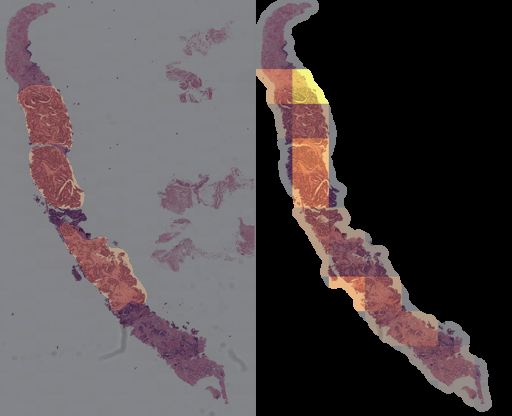

 Cargando WSI desde: /workspace/data/slides_cropped/16B0003394_1.jpg 
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 3.


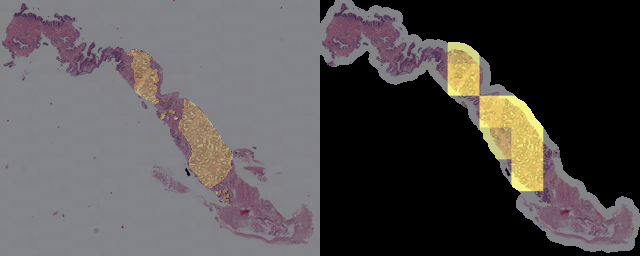

 Cargando WSI desde: /workspace/data/slides_cropped/16B0006668_3.jpg 
 Scores de la slide: Grado Primario = Grade 5 & Grado Secundario = Grade 4.


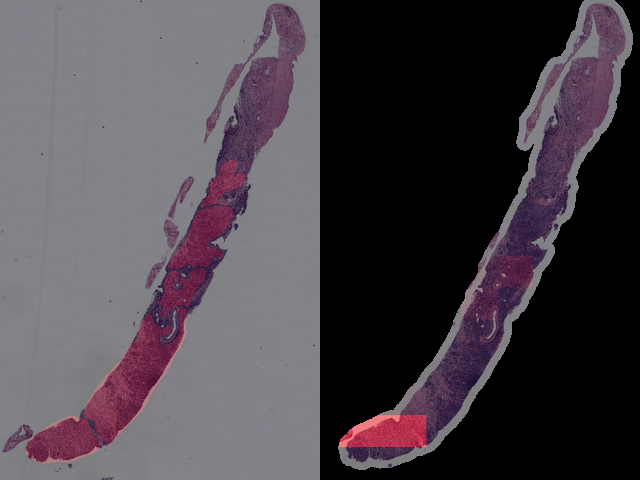

 Cargando WSI desde: /workspace/data/slides_cropped/16B0006694_1.jpg 
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 5.


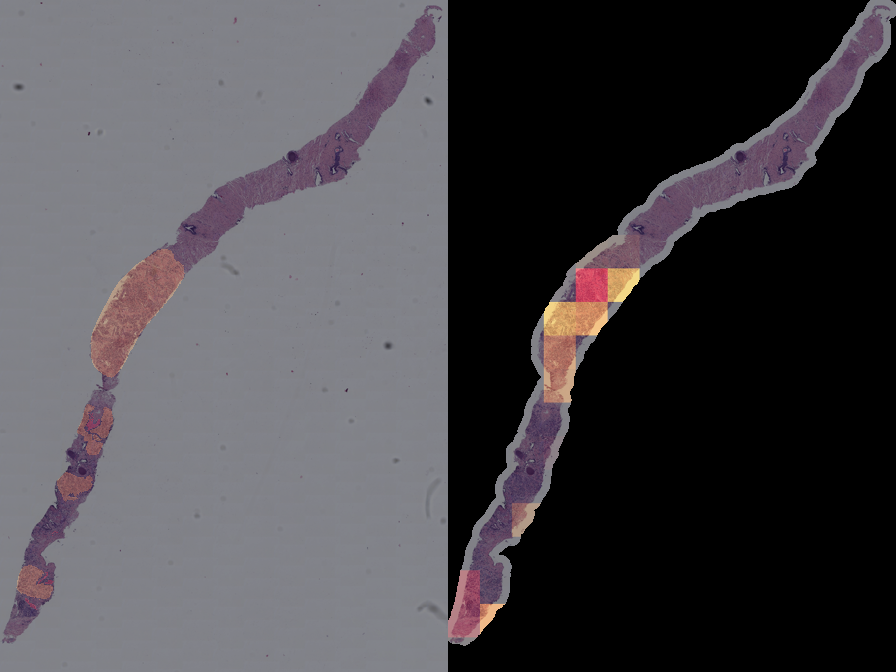

 Cargando WSI desde: /workspace/data/slides_cropped/16B0006695_3.jpg 
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 4.


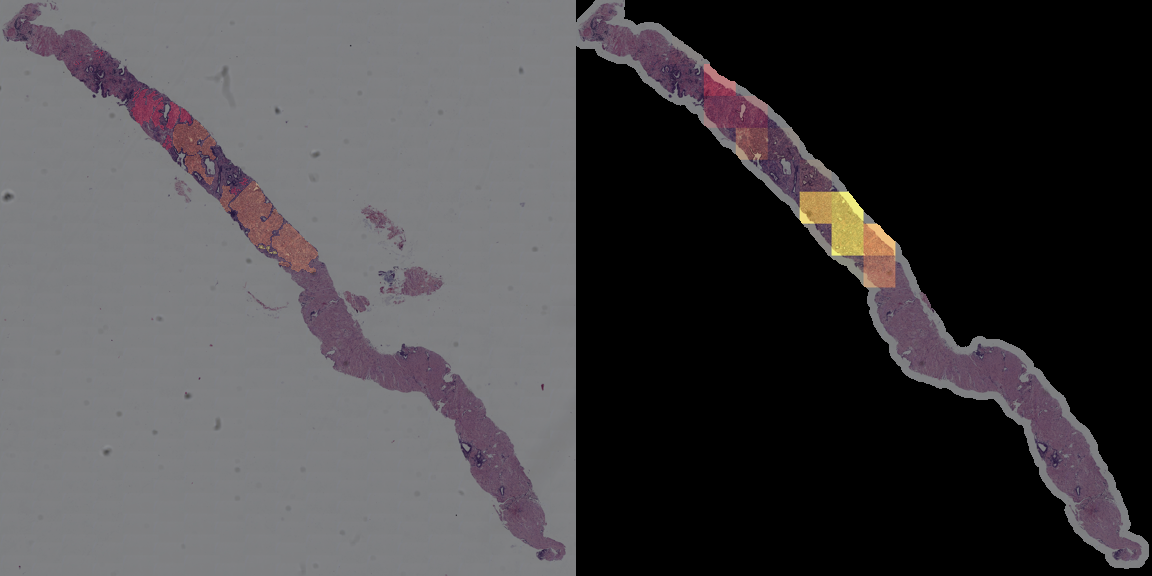

 Cargando WSI desde: /workspace/data/slides_cropped/16B0008066_0.jpg 
 Scores de la slide: Grado Primario = Grade 4 & Grado Secundario = Grade 3.


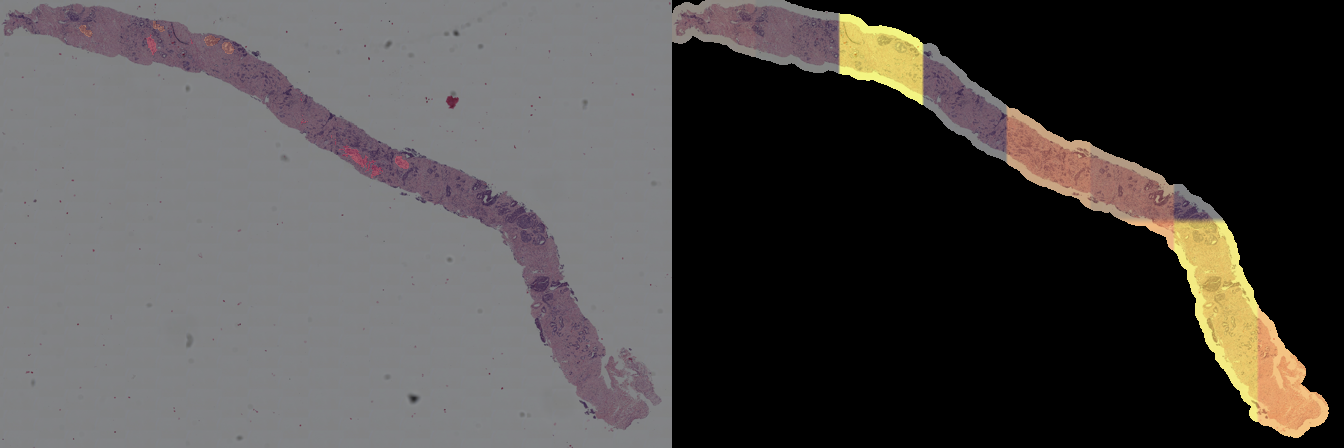

 Cargando WSI desde: /workspace/data/slides_cropped/16B0008067_0.jpg 
 Scores de la slide: Grado Primario = Grade 5 & Grado Secundario = Grade 4.


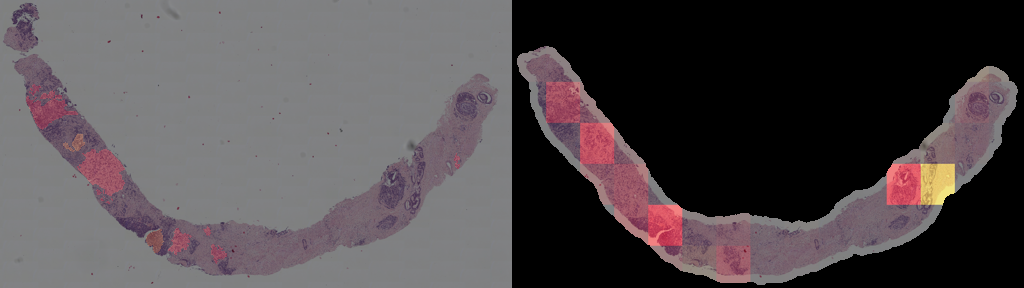

 Cargando WSI desde: /workspace/data/slides_cropped/16B0022610_9.jpg 
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 3.


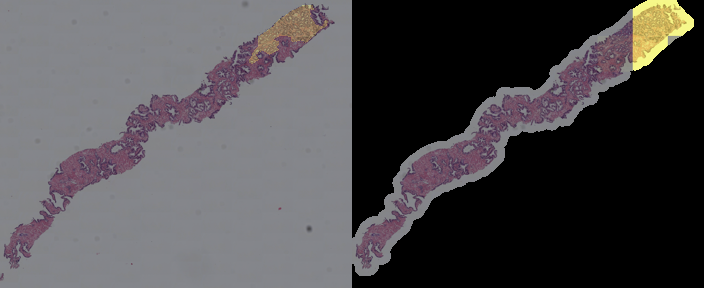

 Cargando WSI desde: /workspace/data/slides_cropped/16B0022612_1.jpg 
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 4.


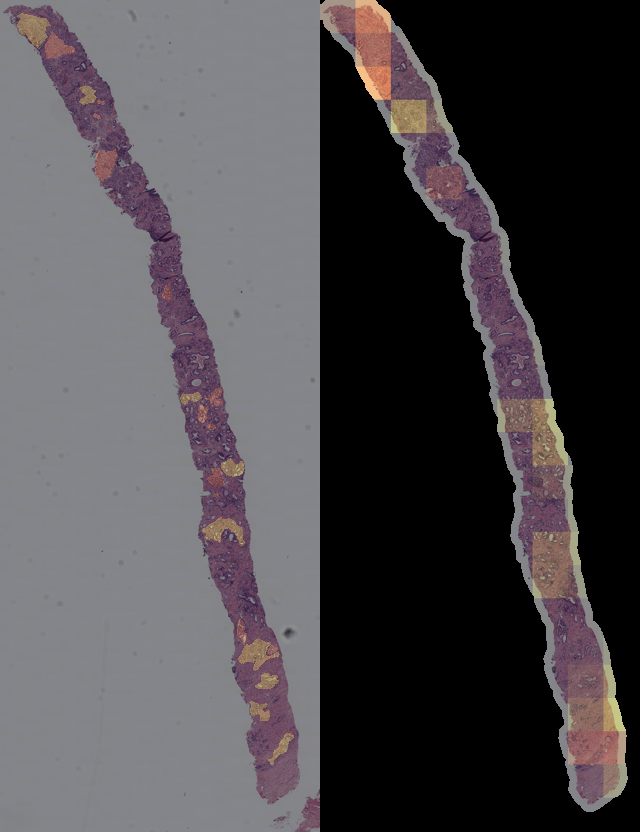

 Cargando WSI desde: /workspace/data/slides_cropped/16B0022613_2.jpg 
 Scores de la slide: Grado Primario = Grade 3 & Grado Secundario = Grade 4.


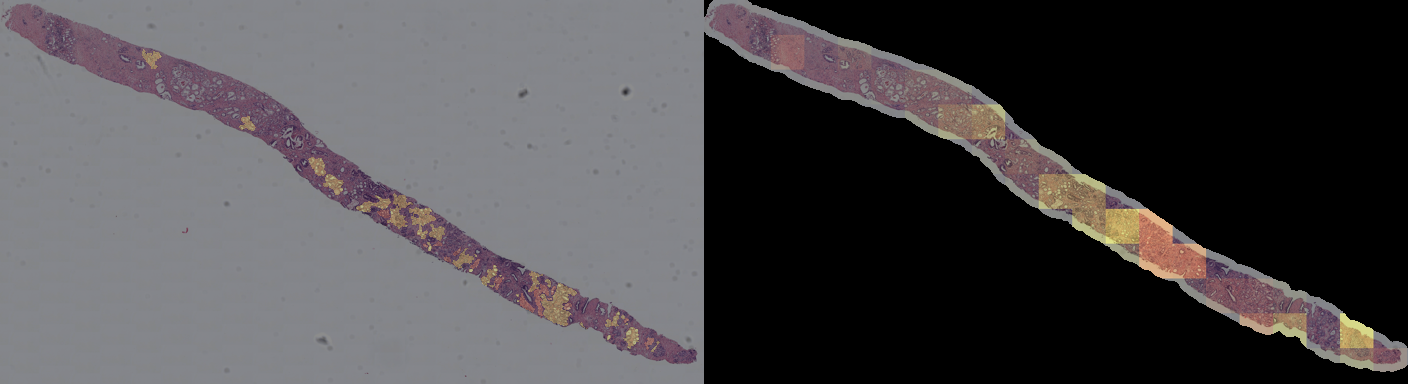

In [33]:
# COMAPRISON OF RESULTS
green_folder = '/workspace/data/features_SICAP/masks'
test_outputs_h = test_outputs.head(num_img_show)

for index, row in test_outputs_h.iterrows():
    slide_id = row['slide_id']

    '''heatmap = build_heatmap(    coords = row['coords'],
                                scores = row['scores'], 
                                weights = row['weights'],
                                patch_size=512,
                                scale_factor=16,
                                save_path=None)''' 
    heatmap = build_heatmap(coords = row['coords'],
                                    weights=row['weights'],
                                    scores = row['scores'],
                                    patch_size=512,
                                    scale_factor=16,
                                    save_path=None)
    # Cargar la WSI original 
    slide_id = slide_id.replace('.h5','') + '.jpg'  # Ajustar extensión si es necesario
    file_name = slide_id.split('/')[-1]
    
    wsi_path = os.path.join(folder_original_imgs,file_name)
   
    print(f" Cargando WSI desde: {wsi_path} ")
    pred_primary, pred_secondary = row['wsi_logits'][0], row['wsi_logits'][1]
    if pred_primary == pred_secondary:
        grades = [pred_primary]
    else:
        grades = [pred_primary, pred_secondary]
    labels_dic = {0: "NC", 1: "Grade 3", 2: "Grade 4", 3: "Grade 5"}
    pred_primary = labels_dic.get(pred_primary.item())
    pred_secondary = labels_dic.get(pred_secondary.item())
    print(f" Scores de la slide: Grado Primario = {pred_primary} & Grado Secundario = {pred_secondary}.")
    orig = Image.open(wsi_path)
    w, h = orig.size
    new_size = (w // 16, h // 16)
    orig = orig.resize(new_size, Image.Resampling.BICUBIC)
    slide_id_png = file_name.replace('.jpg','') + '.png'
    green_path = os.path.join(green_folder,slide_id_png)
    green = Image.open(green_path)
    green = green.resize(new_size, Image.Resampling.BICUBIC)
    #Crear overlay heatmap sobre la imagen
    overlay = overlay_heatmap_on_image(orig, heatmap)
    overlay_green = overlay_inside_green_line(
        green,
        overlay,
        green_thresh=(150, 100, 100)
    )

    # Dibujar parches GT en la imagen real (lado izquierdo)
    orig_with_gt = draw_gt_patches(orig.copy(), file_name, mask_folder)

    # Crear imagen lado a lado
    w2, h2 = orig_with_gt.size
    canvas = Image.new("RGB", (w2*2, h2))
    canvas.paste(orig_with_gt, (0, 0))
    canvas.paste(overlay_green, (w2, 0), overlay_green)

    canvas.show()    

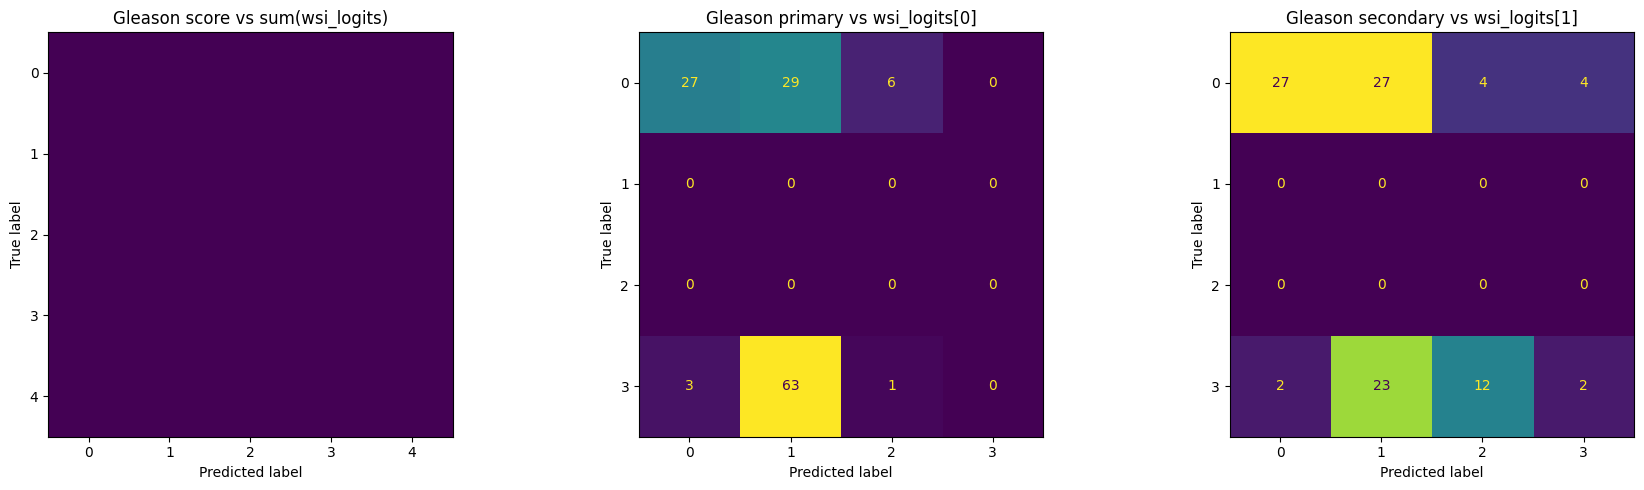

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# -----------------------------
# CONFIGURACIÓN
# -----------------------------

excel_gt = "/workspace/data/wsi_labels_changed_SICAP.xlsx"
df_pred = test_outputs.copy()

# -----------------------------
# CARGA DE DATOS
# -----------------------------

df_pred["image_id"] = (
    df_pred["slide_id"]
    .apply(lambda x: os.path.basename(x))   # 16B0003388_13.h5
    .str.split(".h5").str[0]    # 16B0003388_13
    .str.split("_").str[0]                  # 16B0003388
)
# GT
df_gt = pd.read_excel(excel_gt)
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# =========================
# 1. Merge GT y predicciones
# =========================
df = df_gt.merge(
    df_pred,
    left_on="image_id",
    right_on="image_id",
    how="inner"
)

# =========================
# 2. Extraer predicciones
# =========================
# Primary y secondary desde wsi_logits
df["pred_primary"] = df["wsi_logits"].apply(lambda x: x[0].item())
df["pred_secondary"] = df["wsi_logits"].apply(lambda x: x[1].item())

# Gleason score como suma de logits
df["pred_gleason_score"] = df["wsi_logits"].apply(lambda x: sum(x).item())

# ------------------------------------------------------------------
# ⚠️ SI LOS LOGITS NO SON CLASES ENTERAS, discretiza aquí
# Ejemplo:
df["pred_primary"] = df["pred_primary"].round().astype(int)
df["pred_secondary"] = df["pred_secondary"].round().astype(int)
df["pred_gleason_score"] = df["pred_gleason_score"].round().astype(int)
# ------------------------------------------------------------------

# =========================
# 3. Matrices de confusión
# =========================

# 1️⃣ Gleason score vs suma de wsi_logits
cm_score = confusion_matrix(
    df["gleason_score"],
    df["pred_gleason_score"], labels=[6,7,8,9,10]
)

# 2️⃣ Gleason primary vs primer logit
cm_primary = confusion_matrix(
    df["gleason_primary"],
    df["pred_primary"], labels= [0,1,2,3]
)

# 3️⃣ Gleason secondary vs segundo logit
cm_secondary = confusion_matrix(
    df["gleason_secondary"],
    df["pred_secondary"], labels= [0,1,2,3]
)

# =========================
# 4. Visualización
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

ConfusionMatrixDisplay(cm_score).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Gleason score vs sum(wsi_logits)")

ConfusionMatrixDisplay(cm_primary).plot(ax=axes[1], colorbar=False)
axes[1].set_title("Gleason primary vs wsi_logits[0]")

ConfusionMatrixDisplay(cm_secondary).plot(ax=axes[2], colorbar=False)
axes[2].set_title("Gleason secondary vs wsi_logits[1]")

plt.tight_layout()
plt.show()
